# Vorstudie mit planted effects: MSE vs. SPO+ (lineares Modell, Shortest Path)

**Generator** (`make_data("shortest_path", "planted", …)` in [prestudy.py](../../src/prestudy.py)): wie PyEPO $c = a + \big[(Bx/\sqrt p + 3)^{deg} + 1\big] / 3.5^{deg} \cdot \varepsilon$, aber $a$ und $B$ bewusst gesetzt, k×k-Gitter mit k ∈ {5, 10}, p = 5.

- **Vier konkurrierende Pfade** mit Grundkosten 0: oben-rechts (Treiber x1), links-unten (x2), Treppe (ohne Feature, konstante Referenz), mittlere Zeile (2·(x1 + x2); Faktor 2, weil sie weniger exklusive Kanten hat). Kanten, die genau ein Pfad nutzt, tragen dessen Treiber, geteilte Kanten keinen.
- **Ablenker-Kanten:** alle übrigen, Grundkosten 2 (damit nie optimal), getrieben von x3 und/oder x4.
- **Rauschfeature** x5 wirkt auf keine Kante.

| Gruppe | erwarteter ΔMSE | erwarteter ΔRegret |
|---|---|---|
| kritisch (x1, x2) | groß | groß |
| Ablenker (x3, x4) | groß | ≈ 0 |
| Rauschen (x5) | ≈ 0 | ≈ 0 |

Das Raster, das Training und die PFI sind wie in der ersten Vorstudie (deg ∈ {1, 2, 4, 6}, noise ∈ {0, 0.5}, n ∈ {100, 1000}, m = 5, K = 10, $n_{test}$ = 1000).

In [1]:
import pandas as pd

import prestudy as v

GRIDS = (5, 10)
RUN = dict(degs=(1, 2, 4, 6), noises=(0.0, 0.5), ns=(100, 1000), m=5, n_test=1000, K=10, steps=3000)
CSV = v.result_path("shortest_path", "planted")
pd.set_option("display.precision", 3)

## 1 Generator prüfen (Sekunden)

Kantengruppen im Gitter:

Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16


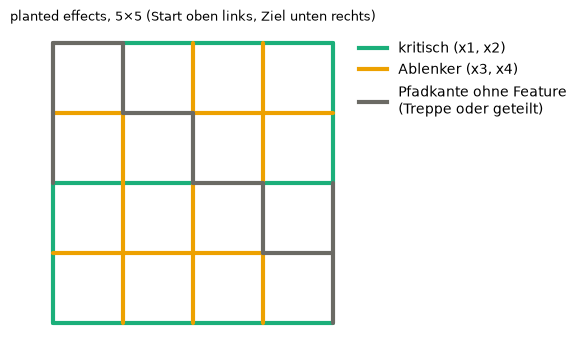

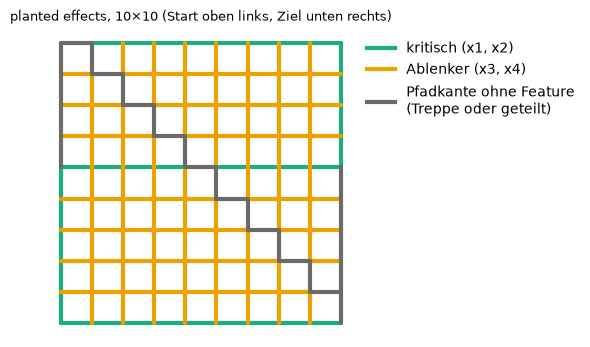

In [2]:
for k in GRIDS:
    v.plot_structure("shortest_path", k)

Wie oft ist welcher Pfad optimal (wahre Kosten, 2000 Instanzen)? `andere` = Mischpfade innerhalb der Korridore. `Ablenker genutzt` muss 0 sein. Zielbereich laut AP 5: Der häufigste Pfad sollte nicht über ca. 70 % liegen.

In [3]:
pd.DataFrame({(k, deg, noise): v.path_shares(k, deg, noise)
              for k in GRIDS for deg in RUN["degs"] for noise in RUN["noises"]}).T.rename_axis(["size", "deg", "noise"])

oben-rechts  links-unten  treppe  mitte     andere  \
size deg noise                                                       
5    1   0.0          0.229        0.245   0.249  0.277  0.000e+00   
         0.5          0.221        0.234   0.169  0.171  2.045e-01   
     2   0.0          0.244        0.280   0.249  0.227  0.000e+00   
         0.5          0.237        0.276   0.207  0.175  1.045e-01   
     4   0.0          0.293        0.341   0.249  0.117  0.000e+00   
         0.5          0.288        0.331   0.231  0.110  4.050e-02   
     6   0.0          0.317        0.365   0.249  0.068  0.000e+00   
         0.5          0.311        0.359   0.240  0.069  2.000e-02   
10   1   0.0          0.217        0.229   0.249  0.304  0.000e+00   
         0.5          0.202        0.232   0.186  0.227  1.530e-01   
     2   0.0          0.227        0.242   0.249  0.282  0.000e+00   
         0.5          0.226        0.252   0.227  0.248  4.800e-02   
     4   0.0          0.266        0.312   0.249  0.173  0.000e+00   
         0.5          0.265        0.318   0.243  0.168  7.000e-03   
     6   0.0          0.301        0.345   0.249  0.104  1.110e-16   
         0.5          0.301        0.343   0.248  0.105  2.500e-03   

                Ablenker genutzt  
size deg noise                    
5    1   0.0                 0.0  
         0.5                 0.0  
     2   0.0                 0.0  
         0.5                 0.0  
     4   0.0                 0.0  
         0.5                 0.0  
     6   0.0                 0.0  
         0.5                 0.0  
10   1   0.0                 0.0  
         0.5                 0.0  
     2   0.0                 0.0  
         0.5                 0.0  
     4   0.0                 0.0  
         0.5                 0.0  
     6   0.0                 0.0  
         0.5                 0.0

## 2 Trainingslauf

Lädt die CSV, falls vorhanden; sonst rechnet er ca. 10 min (5×5) + 30 min (10×10) seriell, parallel deutlich weniger. Für eine Neuberechnung die CSV löschen.

In [4]:
if not CSV.exists():
    pd.concat([v.run("shortest_path", "planted", k, **RUN) for k in GRIDS]).to_csv(CSV, index=False)
df = pd.read_csv(CSV)

## 3 Oracle-Check: PFI der wahren Kostenfunktion

Die Rangfolge muss der geplanten entsprechen: ΔRegret nur bei x1, x2; ΔMSE bei x1–x4; x5 ≈ 0.

In [5]:
(df[df.loss == "oracle"]
 .pivot_table(index=["size", "noise", "deg"], columns="feature", values=["d_mse", "d_regret"]))

d_mse                           d_regret                      
feature            x1     x2     x3     x4   x5       x1     x2   x3   x4   x5
size noise deg                                                                
5    0.0   1    0.014  0.015  0.006  0.010  0.0    0.034  0.037  0.0  0.0  0.0
           2    0.044  0.047  0.018  0.030  0.0    0.074  0.088  0.0  0.0  0.0
           4    0.262  0.289  0.058  0.088  0.0    0.166  0.222  0.0  0.0  0.0
           6    1.896  2.308  0.140  0.205  0.0    0.289  0.398  0.0  0.0  0.0
     0.5   1    0.014  0.016  0.006  0.010  0.0    0.034  0.037  0.0  0.0  0.0
           2    0.044  0.049  0.019  0.030  0.0    0.075  0.089  0.0  0.0  0.0
           4    0.269  0.298  0.058  0.089  0.0    0.168  0.226  0.0  0.0  0.0
           6    1.977  2.393  0.140  0.207  0.0    0.288  0.403  0.0  0.0  0.0
10   0.0   1    0.008  0.009  0.011  0.011  0.0    0.039  0.041  0.0  0.0  0.0
           2    0.025  0.027  0.033  0.032  0.0    0.088  0.095  0.0  0.0  0.0
           4    0.153  0.169  0.098  0.097  0.0    0.200  0.242  0.0  0.0  0.0
           6    1.120  1.362  0.216  0.225  0.0    0.342  0.440  0.0  0.0  0.0
     0.5   1    0.008  0.009  0.011  0.011  0.0    0.042  0.043  0.0  0.0  0.0
           2    0.026  0.027  0.033  0.032  0.0    0.092  0.098  0.0  0.0  0.0
           4    0.155  0.171  0.098  0.097  0.0    0.205  0.246  0.0  0.0  0.0
           6    1.139  1.386  0.215  0.225  0.0    0.349  0.447  0.0  0.0  0.0

## 4 Modellgüte

In [6]:
(v.performance(df).query("loss != 'oracle'")
 .groupby(["size", "noise", "n", "deg", "loss"])[["mse", "mse_adj", "regret"]].mean()
 .unstack("loss"))

mse           mse_adj        regret           
loss                         mse   spo+        mse   spo+    mse       spo+
size noise n      deg                                                      
5    0.0   100.0  1    8.421e-11  4.381  7.507e-12  0.695  0.000  1.033e-03
                  2    2.834e-03  3.305  2.834e-03  0.706  0.002  2.399e-03
                  4    7.788e-02  2.928  7.781e-02  0.902  0.023  7.532e-03
                  6    8.304e-01  5.054  8.292e-01  2.259  0.068  1.345e-02
           1000.0 1    7.370e-11  4.397  4.360e-12  0.675  0.000  5.333e-06
                  2    2.654e-03  3.159  2.653e-03  0.599  0.002  6.922e-04
                  4    7.285e-02  2.990  7.285e-02  0.903  0.024  3.598e-03
                  6    7.757e-01  6.198  7.757e-01  2.297  0.068  3.926e-03
     0.5   100.0  1    1.167e-01  4.137  1.167e-01  0.591  0.067  7.191e-02
                  2    7.034e-02  3.094  7.034e-02  0.601  0.040  4.244e-02
                  4    1.473e-01  2.837  1.472e-01  0.877  0.046  3.599e-02
                  6    1.086e+00  4.863  1.085e+00  2.437  0.088  3.934e-02
           1000.0 1    1.105e-01  4.156  1.105e-01  0.564  0.064  6.359e-02
                  2    6.649e-02  3.101  6.649e-02  0.573  0.038  3.811e-02
                  4    1.385e-01  2.746  1.385e-01  0.811  0.046  2.873e-02
                  6    1.020e+00  4.641  1.021e+00  2.384  0.085  2.589e-02
10   0.0   100.0  1    1.634e-10  6.243  1.394e-11  0.642  0.000  1.515e-03
                  2    1.951e-03  4.820  1.952e-03  0.635  0.002  2.513e-03
                  4    5.210e-02  4.096  5.210e-02  0.749  0.021  1.072e-02
                  6    5.223e-01  5.297  5.215e-01  1.640  0.064  1.919e-02
           1000.0 1    1.407e-10  6.046  7.553e-12  0.586  0.000  1.152e-05
                  2    1.814e-03  4.553  1.814e-03  0.538  0.002  3.219e-04
                  4    4.824e-02  3.980  4.824e-02  0.710  0.021  5.076e-03
                  6    4.839e-01  5.629  4.840e-01  1.648  0.060  7.890e-03
     0.5   100.0  1    1.175e-01  5.676  1.175e-01  0.544  0.034  3.613e-02
                  2    6.920e-02  4.459  6.920e-02  0.560  0.019  2.029e-02
                  4    1.105e-01  3.981  1.105e-01  0.745  0.032  1.930e-02
                  6    6.655e-01  5.306  6.646e-01  1.761  0.072  2.551e-02
           1000.0 1    1.109e-01  5.558  1.109e-01  0.507  0.031  3.071e-02
                  2    6.524e-02  4.306  6.524e-02  0.506  0.017  1.516e-02
                  4    1.034e-01  3.847  1.034e-01  0.703  0.030  1.341e-02
                  6    6.241e-01  5.206  6.242e-01  1.725  0.068  1.479e-02

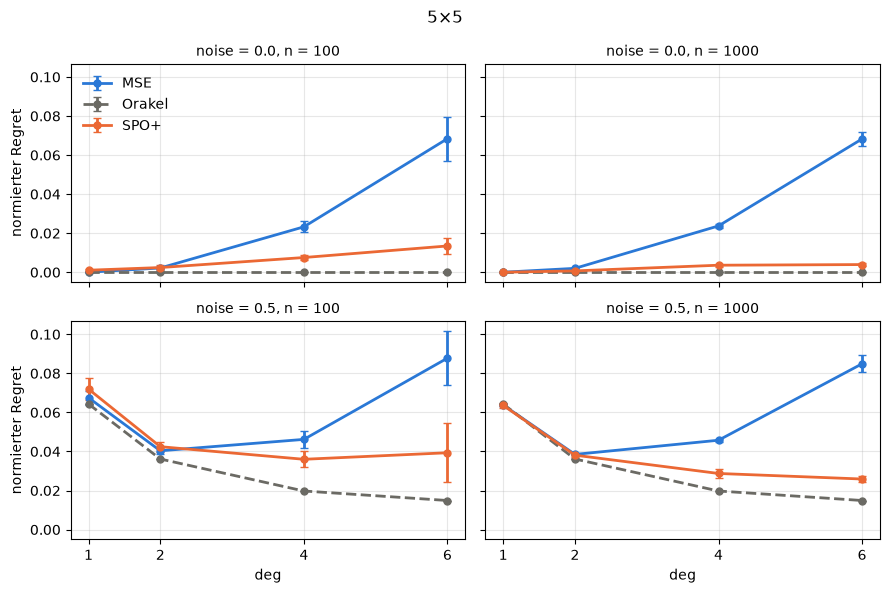

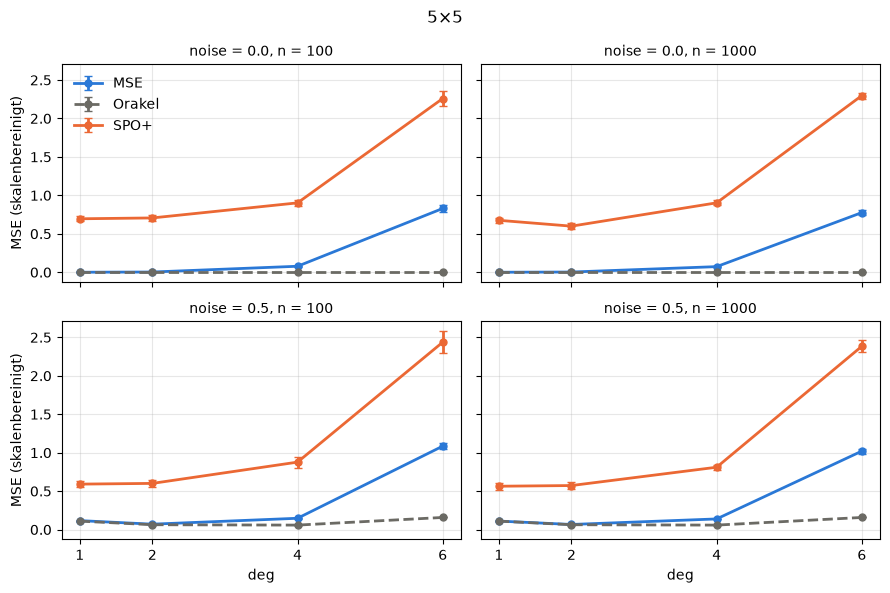

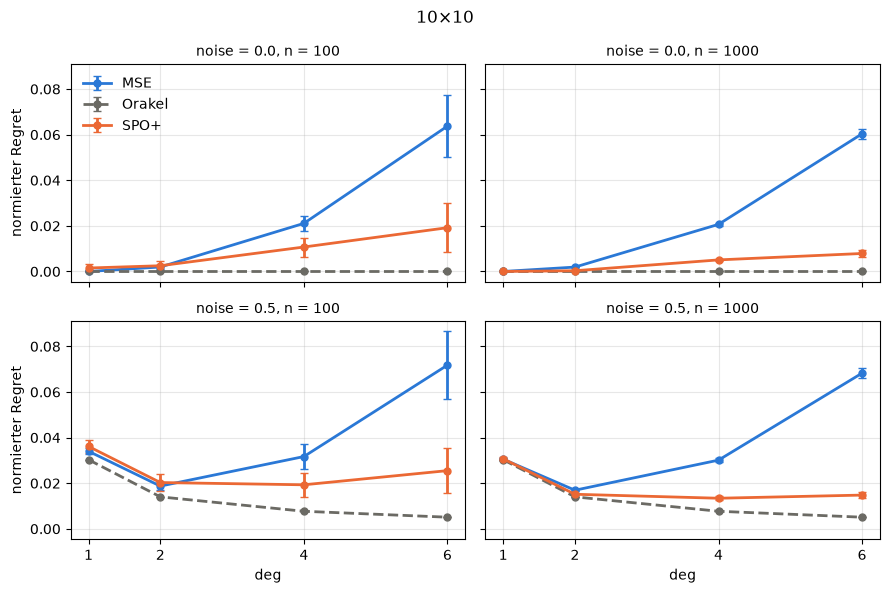

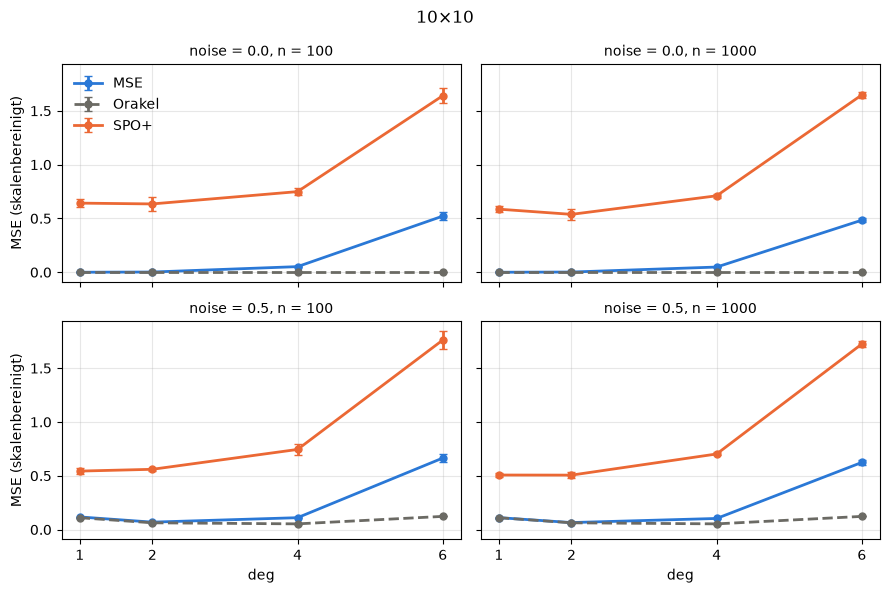

In [7]:
for k, g in df.groupby("size"):
    v.plot_over_deg(g, "regret", "normierter Regret", f"{k}×{k}")
    v.plot_over_deg(g, "mse_adj", "MSE (skalenbereinigt)", f"{k}×{k}")

## 5 PFI je Feature (n = 1000, noise = 0.5)

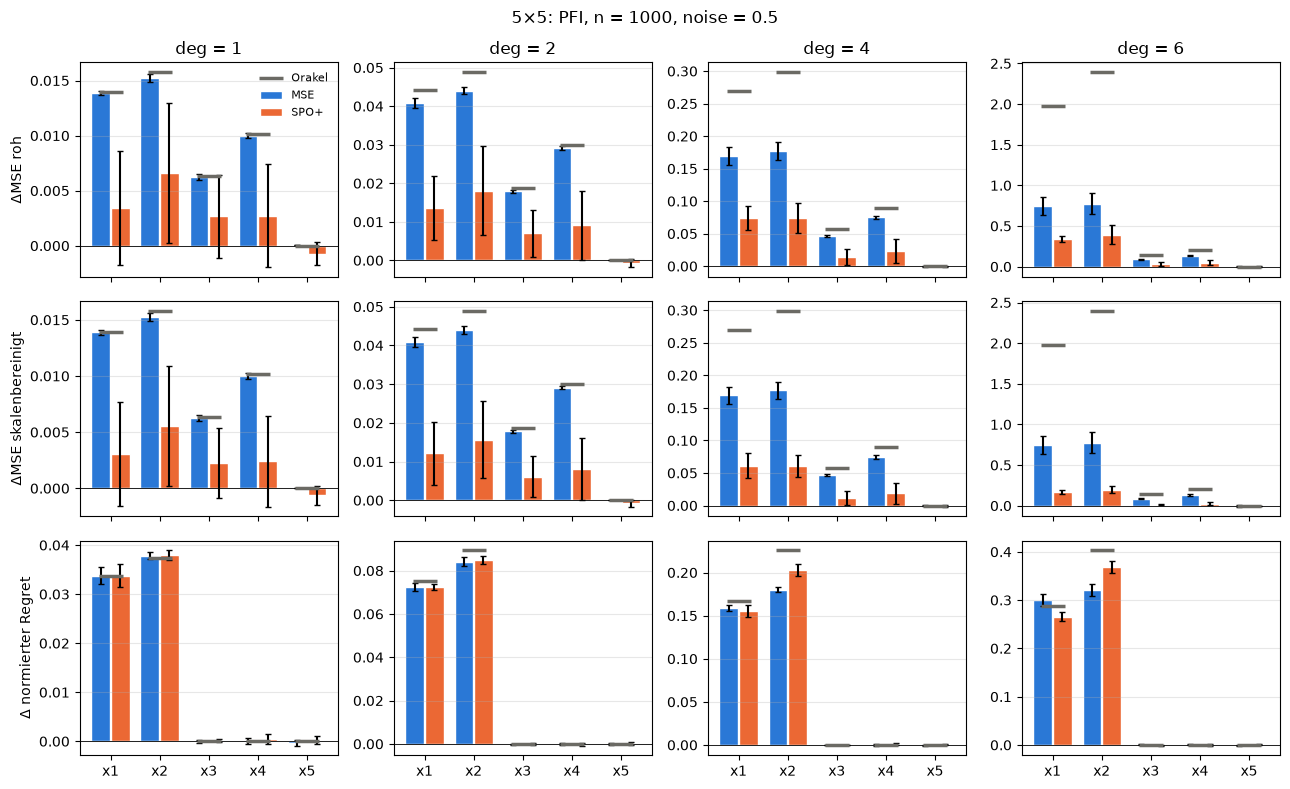

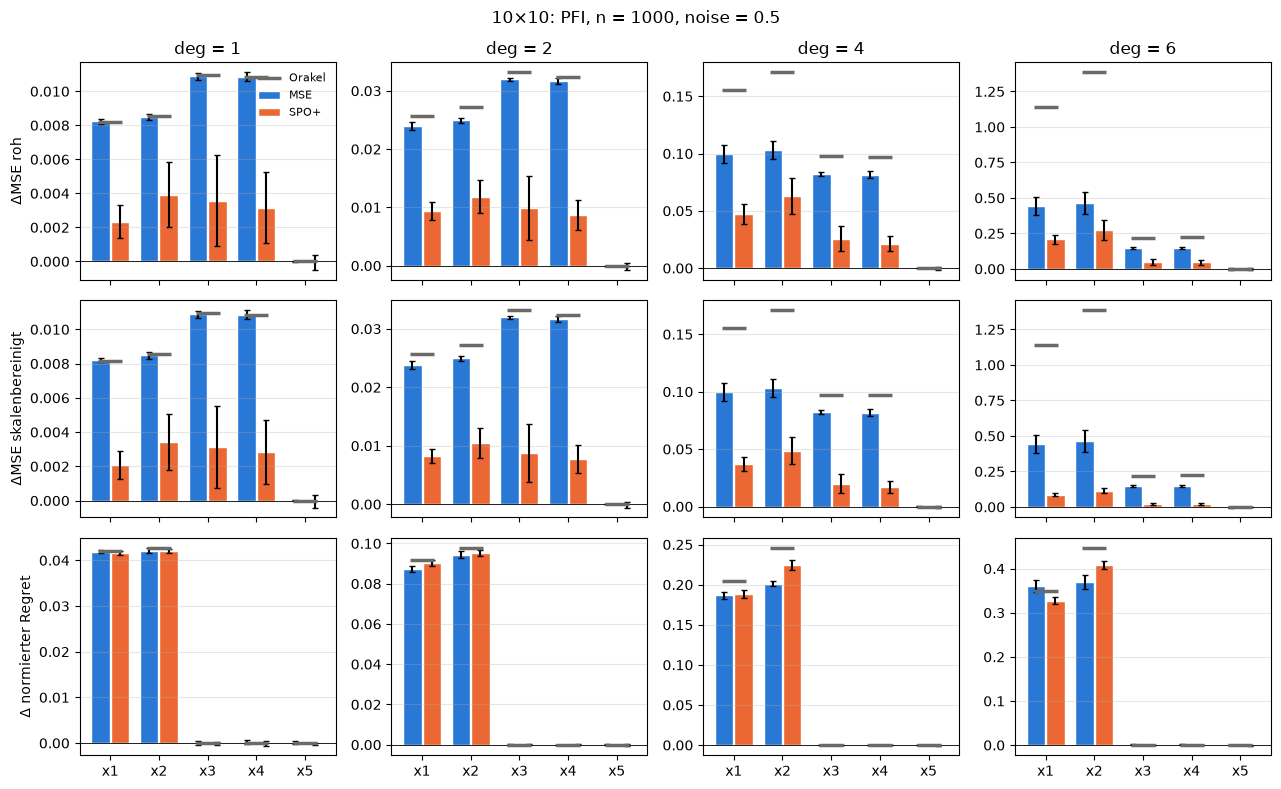

In [8]:
for k, g in df.groupby("size"):
    v.plot_pfi(g, title=f"{k}×{k}:")

## 6 H2: Anteil der Wichtigkeit auf kritischen Features und Ablenkern

Anteil an der Summe der (bei 0 abgeschnittenen) PFI-Werte, je Refit berechnet, dann gemittelt. Erwartung: Beim ΔRegret liegt fast alles auf den kritischen Features. Beim ΔMSE hat das MSE-Modell einen großen Anteil auf den Ablenkern, SPO+ einen kleineren.

In [9]:
def share(df, measure, feats):
    vals = df[measure].clip(lower=0)
    keys = ["size", "noise", "n", "deg", "loss", "refit"]
    g = (pd.DataFrame({"part": vals.where(df.feature.isin(feats), 0), "total": vals})
         .groupby([df[c] for c in keys], dropna=False).sum())
    return (g.part / g.total).groupby(level=keys[:-1], dropna=False).mean().unstack("loss")


GROUPS = {"kritisch": ["x1", "x2"], "Ablenker": ["x3", "x4"]}
h2 = pd.concat({(m, grp): share(df, m, f) for m in ("d_mse_adj", "d_regret") for grp, f in GROUPS.items()}, axis=1)
h2.xs(0.5, level="noise")

d_mse_adj                                      d_regret  \
                 kritisch               Ablenker               kritisch   
loss                  mse oracle   spo+      mse oracle   spo+      mse   
size n      deg                                                           
5    100.0  1       0.649    NaN  0.678    0.351    NaN  0.317    0.984   
            2       0.646    NaN  0.711    0.354    NaN  0.286    0.995   
            4       0.732    NaN  0.841    0.268    NaN  0.158    0.997   
            6       0.858    NaN  0.930    0.142    NaN  0.067    0.995   
     1000.0 1       0.642    NaN  0.618    0.358    NaN  0.373    0.996   
            2       0.644    NaN  0.651    0.356    NaN  0.347    0.998   
            4       0.739    NaN  0.799    0.260    NaN  0.200    0.999   
            6       0.870    NaN  0.900    0.129    NaN  0.098    0.998   
     NaN    1         NaN  0.643    NaN      NaN  0.357    NaN      NaN   
            2         NaN  0.656    NaN      NaN  0.344    NaN      NaN   
            4         NaN  0.794    NaN      NaN  0.206    NaN      NaN   
            6         NaN  0.927    NaN      NaN  0.073    NaN      NaN   
10   100.0  1       0.433    NaN  0.494    0.565    NaN  0.494    0.994   
            2       0.432    NaN  0.575    0.568    NaN  0.421    0.997   
            4       0.540    NaN  0.702    0.460    NaN  0.295    0.998   
            6       0.729    NaN  0.862    0.271    NaN  0.137    0.996   
     1000.0 1       0.435    NaN  0.478    0.565    NaN  0.513    0.994   
            2       0.434    NaN  0.533    0.566    NaN  0.464    0.999   
            4       0.553    NaN  0.700    0.447    NaN  0.298    0.999   
            6       0.753    NaN  0.840    0.247    NaN  0.160    0.998   
     NaN    1         NaN  0.434    NaN      NaN  0.566    NaN      NaN   
            2         NaN  0.446    NaN      NaN  0.554    NaN      NaN   
            4         NaN  0.627    NaN      NaN  0.373    NaN      NaN   
            6         NaN  0.852    NaN      NaN  0.148    NaN      NaN   

                                                            
                                Ablenker                    
loss            oracle   spo+        mse oracle       spo+  
size n      deg                                             
5    100.0  1      NaN  0.983  6.815e-03    NaN  1.256e-02  
            2      NaN  0.996  3.575e-03    NaN  1.912e-03  
            4      NaN  0.995  1.694e-03    NaN  2.964e-03  
            6      NaN  0.995  3.380e-03    NaN  2.537e-03  
     1000.0 1      NaN  0.986  3.438e-03    NaN  9.242e-03  
            2      NaN  0.997  1.016e-03    NaN  1.589e-03  
            4      NaN  0.997  7.835e-04    NaN  2.553e-03  
            6      NaN  0.998  1.845e-03    NaN  1.169e-03  
     NaN    1      1.0    NaN        NaN    0.0        NaN  
            2      1.0    NaN        NaN    0.0        NaN  
            4      1.0    NaN        NaN    0.0        NaN  
            6      1.0    NaN        NaN    0.0        NaN  
10   100.0  1      NaN  0.992  4.685e-03    NaN  3.462e-03  
            2      NaN  0.995  1.591e-03    NaN  3.099e-03  
            4      NaN  0.998  1.452e-03    NaN  1.176e-03  
            6      NaN  0.998  3.228e-03    NaN  9.693e-04  
     1000.0 1      NaN  0.998  4.899e-03    NaN  2.262e-03  
            2      NaN  0.998  5.472e-04    NaN  1.536e-03  
            4      NaN  1.000  4.384e-04    NaN  3.869e-04  
            6      NaN  0.999  1.869e-03    NaN  2.346e-04  
     NaN    1      1.0    NaN        NaN    0.0        NaN  
            2      1.0    NaN        NaN    0.0        NaN  
            4      1.0    NaN        NaN    0.0        NaN  
            6      1.0    NaN        NaN    0.0        NaN

## 7 H1: Rangfolge nach ΔMSE vs. ΔRegret (Kendall's τ)

In [10]:
pd.concat({k: v.kendall_tau(g) for k, g in df.groupby("size")}, names=["size"])

loss                    mse  oracle  spo+
size noise n      deg                    
5    0.0   100.0  1    0.84     NaN  0.68
                  2    0.88     NaN  0.64
                  4    0.72     NaN  0.64
                  6    0.84     NaN  0.64
           1000.0 1    0.84     NaN  0.60
                  2    0.64     NaN  0.52
                  4    0.88     NaN  0.64
                  6    0.64     NaN  0.64
           NaN    1     NaN    0.84   NaN
                  2     NaN    0.84   NaN
                  4     NaN    0.84   NaN
                  6     NaN    0.84   NaN
     0.5   100.0  1    0.56     NaN  0.32
                  2    0.72     NaN  0.56
                  4    0.48     NaN  0.56
                  6    0.68     NaN  0.60
           1000.0 1    0.68     NaN  0.28
                  2    0.84     NaN  0.36
                  4    0.76     NaN  0.56
                  6    0.68     NaN  0.56
           NaN    1     NaN    0.84   NaN
                  2     NaN    0.84   NaN
                  4     NaN    0.84   NaN
                  6     NaN    0.84   NaN
10   0.0   100.0  1   -0.12     NaN  0.60
                  2    0.04     NaN  0.68
                  4    0.60     NaN  0.60
                  6    0.72     NaN  0.60
           1000.0 1   -0.12     NaN  0.72
                  2   -0.08     NaN  0.40
                  4    0.60     NaN  0.64
                  6    0.76     NaN  0.52
           NaN    1     NaN   -0.12   NaN
                  2     NaN   -0.12   NaN
                  4     NaN    0.84   NaN
                  6     NaN    0.84   NaN
     0.5   100.0  1   -0.20     NaN  0.16
                  2   -0.16     NaN  0.52
                  4    0.60     NaN  0.72
                  6    0.80     NaN  0.48
           1000.0 1    0.00     NaN  0.36
                  2   -0.16     NaN  0.56
                  4    0.64     NaN  0.80
                  6    0.68     NaN  0.68
           NaN    1     NaN   -0.12   NaN
                  2     NaN   -0.12   NaN
                  4     NaN    0.84   NaN
                  6     NaN    0.84   NaN

## 8 Loss-Effekt je Feature: gepaarte Differenz SPO+ − MSE (n = 1000, noise = 0.5)

`*` = 95-%-Intervall schließt 0 aus (ohne Holm-Korrektur, Pilot).

In [11]:
pd.concat({k: v.paired_diff(g).unstack("deg").loc[(0.5, 1000)] for k, g in df.groupby("size")}, names=["size"])

d_mse_adj                                          \
deg                            1                   2                   4   
size feature                                                               
5    x1       -0.0108 ± 0.0048 *  -0.0287 ± 0.0092 *  -0.1081 ± 0.0282 *   
     x2       -0.0097 ± 0.0054 *  -0.0284 ± 0.0095 *  -0.1165 ± 0.0171 *   
     x3       -0.0040 ± 0.0029 *  -0.0118 ± 0.0050 *  -0.0351 ± 0.0097 *   
     x4       -0.0076 ± 0.0040 *  -0.0210 ± 0.0078 *  -0.0560 ± 0.0138 *   
     x5         -0.0007 ± 0.0009    -0.0007 ± 0.0009    -0.0004 ± 0.0009   
10   x1       -0.0062 ± 0.0009 *  -0.0156 ± 0.0018 *  -0.0626 ± 0.0104 *   
     x2       -0.0050 ± 0.0018 *  -0.0145 ± 0.0025 *  -0.0544 ± 0.0085 *   
     x3       -0.0077 ± 0.0022 *  -0.0232 ± 0.0047 *  -0.0622 ± 0.0073 *   
     x4       -0.0080 ± 0.0020 *  -0.0239 ± 0.0026 *  -0.0650 ± 0.0052 *   
     x5         -0.0000 ± 0.0004    -0.0001 ± 0.0005    -0.0001 ± 0.0010   

                                          d_regret                      \
deg                            6                 1                   2   
size feature                                                             
5    x1       -0.5764 ± 0.1168 *  -0.0001 ± 0.0009    -0.0001 ± 0.0008   
     x2       -0.5791 ± 0.0986 *  +0.0001 ± 0.0012    +0.0008 ± 0.0009   
     x3       -0.0734 ± 0.0105 *  +0.0002 ± 0.0005    +0.0001 ± 0.0004   
     x4       -0.1094 ± 0.0107 *  +0.0004 ± 0.0009    -0.0002 ± 0.0007   
     x5         +0.0021 ± 0.0068  +0.0006 ± 0.0014    +0.0003 ± 0.0004   
10   x1       -0.3551 ± 0.0588 *  -0.0002 ± 0.0006  +0.0030 ± 0.0006 *   
     x2       -0.3485 ± 0.0719 *  -0.0001 ± 0.0006  +0.0008 ± 0.0006 *   
     x3       -0.1266 ± 0.0057 *  -0.0001 ± 0.0006    +0.0001 ± 0.0002   
     x4       -0.1289 ± 0.0096 *  -0.0003 ± 0.0006  +0.0002 ± 0.0002 *   
     x5         +0.0005 ± 0.0041  -0.0002 ± 0.0004    -0.0002 ± 0.0002   

                                                      
deg                            4                   6  
size feature                                          
5    x1         -0.0041 ± 0.0052  -0.0349 ± 0.0195 *  
     x2       +0.0225 ± 0.0064 *  +0.0473 ± 0.0126 *  
     x3         +0.0002 ± 0.0005    -0.0009 ± 0.0012  
     x4         +0.0008 ± 0.0016    +0.0000 ± 0.0007  
     x5         +0.0004 ± 0.0008    +0.0002 ± 0.0016  
10   x1         +0.0012 ± 0.0023  -0.0325 ± 0.0116 *  
     x2       +0.0232 ± 0.0058 *  +0.0387 ± 0.0112 *  
     x3         +0.0001 ± 0.0005    -0.0005 ± 0.0016  
     x4         -0.0001 ± 0.0003    -0.0008 ± 0.0012  
     x5       -0.0003 ± 0.0002 *    -0.0003 ± 0.0012